## Assigmet 3 Mideterm 2
Author: FIlippo Alessandro Sandoval Villarreal

In this assigment i will implemetn a Restricted Boltzman Machine from schratch. The RBM will be trained over a dataset of images (available at this link: )

In [16]:
import pandas as pd
from PIL import Image
import io
import matplotlib.pyplot as plt
import numpy as np

Voglio andare a vedere di quale tipo sono le immagini

In [17]:
# i open the parquet file with pandas so i can see the binary nature of the immages

img_bin= pd.read_parquet('train-00000-of-00001.parquet')
img_bin.head(5)

,image,label
0,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,5
1,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,0
2,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,4
3,"{'bytes': b""\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...",1
4,{'bytes': b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHD...,9


Now i want to see what kind of images we got in our database. First i wrote a function called decoding image that takes the bytes of the immage and then recostruct it in order to see it.

In [18]:
def decoding_img (img_byte) :
    try:
        #we are going to decode the image 
        d_im= Image.open(io.BytesIO(img_byte))
        #now we plot an immage
        plt.imshow(d_im)
    except Exception as e:
        print("Error in the image decoding")

In the cell below i show the firts 5 pictures

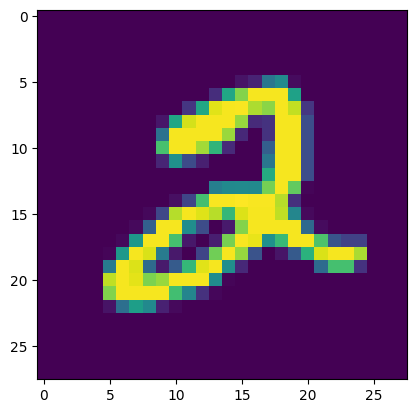

In [19]:
# we take the column that corrispond to the values in bytes of the immage 
img= img_bin['image']

# we show the recostruction for the first image
decoding_img(img[5]['bytes'])


Before the implementattion of the restricted Boltzman Machine i prepare the data for the training of 
it, so i encode the information of the immages in a bynary way, strating from the Byte configuration.

In [20]:
def Binarize_img (img_bytes, target_size=(28,28), threshold=0.5):
    # i rebuild the image 
    img_r= Image.open(io.BytesIO(img_bytes)).resize(target_size).convert('L')
    img_array= np.array(img_r)/255.0
    binary_img = (img_array>threshold).astype(int)
    return binary_img.flatten()

Once i have written the function in order to binarize the values of the image, i apply this to all the images that i have in input

In [21]:
input_bin_im = []

for i in range (0,len(img)):
    bin_im = Binarize_img(img[i]['bytes'])
    input_bin_im.append(bin_im)
input_bin_im = np.array(input_bin_im)

### Restricted Boltzaman Machine

In [22]:
import numpy as np

class RBM:
    def __init__(self, n_visible, n_hidden, random_seed=None):
        """Initializes the RBM."""
        self.n_visible = n_visible
        self.n_hidden = n_hidden
        self.random_state = np.random.RandomState(random_seed)
        self.W = self.random_state.randn(n_visible, n_hidden) * 0.01
        self.b_v = np.zeros(n_visible)
        self.b_h = np.zeros(n_hidden)

    def _sigmoid(self, x):
        """Sigmoid activation function."""
        return 1 / (1 + np.exp(-x))

    def _sample_prob(self, prob):
        """Samples binary states from probabilities."""
        return self.random_state.rand(*prob.shape) < prob

    def visible_to_hidden(self, v):
        """Calculates hidden probabilities and samples given visible units."""
        prob_h = self._sigmoid(np.dot(v, self.W) + self.b_h)
        sample_h = self._sample_prob(prob_h)
        return prob_h, sample_h

    def hidden_to_visible(self, h):
        """Calculates visible probabilities and samples given hidden units."""
        prob_v = self._sigmoid(np.dot(h, self.W.T) + self.b_v)
        sample_v = self._sample_prob(prob_v)
        return prob_v, sample_v

    def contrastive_divergence(self, v_0, k=1, learning_rate=0.1):
        """Performs one step of Contrastive Divergence."""
        batch_size = v_0.shape[0]

        # Positive phase
        prob_h_0, sample_h_0 = self.visible_to_hidden(v_0)

        # Negative phase (k steps of Gibbs sampling)
        v_k = v_0
        h_k = sample_h_0
        for _ in range(k):
            prob_v_k, v_k = self.hidden_to_visible(h_k)
            prob_h_k, h_k = self.visible_to_hidden(v_k)

        # Update weights and biases
        dW = (np.dot(v_0.T, prob_h_0) - np.dot(v_k.T, prob_h_k)) / batch_size
        db_v = np.mean(v_0 - v_k, axis=0)
        db_h = np.mean(prob_h_0 - prob_h_k, axis=0)

        self.W += learning_rate * dW
        self.b_v += learning_rate * db_v
        self.b_h += learning_rate * db_h

        # Reconstruction error (optional, for monitoring training)
        reconstruction_error = np.mean((v_0 - prob_v_k) ** 2)
        return reconstruction_error

    def train(self, data, epochs=10, batch_size=32, learning_rate=0.1, k=1):
        """Trains the RBM on the given data."""
        n_samples = data.shape[0]
        for epoch in range(epochs):
            indices = np.arange(n_samples)
            self.random_state.shuffle(indices)
            for i in range(0, n_samples, batch_size):
                batch_indices = indices[i:i + batch_size]
                batch_data = data[batch_indices]
                reconstruction_error = self.contrastive_divergence(batch_data, k, learning_rate)
            print(f"Epoch {epoch+1}/{epochs}, Reconstruction Error: {reconstruction_error:.4f}")

    def get_hidden_representation(self, v):
        """Returns the probabilities of the hidden units given a visible input."""
        prob_h, _ = self.visible_to_hidden(v)
        return prob_h

    def reconstruct(self, v):
        """Reconstructs the visible units given an input."""
        _, h = self.visible_to_hidden(v)
        prob_v, _ = self.hidden_to_visible(h)
        return prob_v